In [13]:
import pandas as pd
data=pd.read_csv("SwiftCart_Cleaned_Dataset.csv")
data["date"] = pd.to_datetime(data["date"], errors="coerce")
data['ship_postal_code'] = data['ship_postal_code'].astype('Int64').astype('string')

In [33]:
# Remove trailing .0 only when it appears at the end
data["customer_id"] = (
    data["customer_id"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

# Verify the last five records
display(data[["customer_id"]].tail(5))

print("Data type:", data["customer_id"].dtype)
print("Unique customer IDs:", data["customer_id"].nunique())
print("Missing customer IDs:", data["customer_id"].isna().sum())

,customer_id
31042,4724097
31043,4724097
31044,3572295
31045,1423498
31046,4694875


Data type: string
Unique customer IDs: 28394
Missing customer IDs: 41


**Exploratary Data Analysis & Visualization**

**1.Descriptive Analysis**

In [35]:
# Check dataset dimensions
print("Dataset shape:", data.shape)

# Standardize column names for consistent coding
data.columns = (
    data.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

# Restore correct data types after reading CSV
data["date"] = pd.to_datetime(data["date"], errors="coerce")

data["ship_postal_code"] = (
    pd.to_numeric(data["ship_postal_code"], errors="coerce")
    .astype("Int64")
)

# Verify columns and data types
print("\nColumn names:")
print(data.columns.tolist())

print("\nData types:")
data.info()

# Check missing values
print("\nMissing values:")
display(data.isnull().sum().sort_values(ascending=False))

# Descriptive statistics
print("\nNumerical summary:")
display(data.describe())

# Percentiles for important numerical columns
print("\nSelected percentiles:")
display(
    data[["age", "quantity", "amount"]].quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)


Dataset shape: (31047, 21)

Column names:
['index', 'order_id', 'customer_id', 'gender', 'age', 'age_group', 'date', 'month', 'status', 'channel', 'sku', 'category', 'size', 'quantity', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'b2b']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31047 entries, 0 to 31046
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   index             31047 non-null  int64         
 1   order_id          29967 non-null  object        
 2   customer_id       31006 non-null  string        
 3   gender            31047 non-null  object        
 4   age               31047 non-null  int64         
 5   age_group         31047 non-null  object        
 6   date              30559 non-null  datetime64[ns]
 7   month             30582 non-null  object        
 8   status            31047 non-null  object        
 9   c

order_id            1080
date                 488
month                465
customer_id           41
ship_postal_code      10
index                  0
quantity               0
ship_country           0
ship_state             0
ship_city              0
amount                 0
currency               0
sku                    0
size                   0
category               0
channel                0
status                 0
age_group              0
age                    0
gender                 0
b2b                    0
dtype: int64


Numerical summary:


,index,age,date,quantity,amount,ship_postal_code
count,31047.000000,31047.000000,30559,31047.00000,31047.000000,31037.0
mean,15651.589558,39.392985,2022-06-15 07:40:05.929513216,1.01195,682.074822,460474.584979
min,1.000000,18.000000,2022-01-04 00:00:00,1.00000,229.000000,110001.0
25%,7764.500000,28.000000,2022-03-06 00:00:00,1.00000,486.000000,313001.0
50%,15530.000000,37.000000,2022-06-06 00:00:00,1.00000,646.000000,500028.0
75%,23298.500000,47.000000,2022-09-06 00:00:00,1.00000,794.000000,600040.0
max,310760.000000,78.000000,2022-12-06 00:00:00,20.00000,3036.000000,855117.0
std,10280.077476,14.844391,NaN,0.29197,268.582173,198138.926926



Selected percentiles:


,age,quantity,amount
0.25,28.0,1.0,486.0
0.50,37.0,1.0,646.0
0.75,47.0,1.0,794.0
0.90,63.0,1.0,1099.0
0.95,71.0,1.0,1186.0
0.99,77.0,1.0,1442.0


1. Dataset overview — interpretation
Metric result	Meaning
Rows	31,047	Each row represents a dataset record
Columns	21	Customer, order, product, sales and location details
Unique SKUs	5,287	5,287 distinct product codes
Categories	8	Eight product categories
Sales channels	7	Seven channel values
States	35	35 distinct shipping-state values
Amount values	769	769 distinct recorded amount values
Missing order IDs	1,080	Some records cannot be identified by order_id
Missing customer IDs	41	A small number lack a customer identifier
Missing dates	488	Some records cannot be used directly in date-based analysis

Average recorded amount
₹682.07
Mean amount per row

Median recorded amount
₹646
50th percentile



Average age
39.4 years

Median age
37 years



Quantity median
1

Quantity maximum
20
Mean vs median amount: Mean ₹682 is higher than median ₹646. This suggests some higher-value records may be pulling the average upward. We will inspect the distribution to confirm.

Age: The middle 50% of ages fall between 28 and 47 years (Q1–Q3). The average age is around 39.

Quantity: At least 75% of records have quantity 1, because the 75th percentile is also 1. Most recorded quantities are therefore small, but the maximum of 20 deserves further inspection.

Amount: The 99th percentile is ₹1,442, while the maximum is ₹3,036. Some records are much higher than the typical amount, but that does not automatically make them errors.

In [39]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = ["age", "quantity", "amount"]

# Central tendency, dispersion, minimum, maximum and percentiles
summary = data[numeric_cols].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

summary["median"] = data[numeric_cols].median()
summary["variance"] = data[numeric_cols].var()
summary["range"] = (
    data[numeric_cols].max() - data[numeric_cols].min()
)
summary["IQR"] = (
    data[numeric_cols].quantile(0.75)
    - data[numeric_cols].quantile(0.25)
)
summary["skewness"] = data[numeric_cols].skew()

display(summary.round(2))


,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max,median,variance,range,IQR,skewness
age,31047.0,39.39,14.84,18.0,22.0,28.0,37.0,47.0,63.0,71.0,77.0,78.0,37.0,220.36,60,19.0,0.76
quantity,31047.0,1.01,0.29,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,20.0,1.0,0.09,19,0.0,43.73
amount,31047.0,682.07,268.58,229.0,380.0,486.0,646.0,794.0,1099.0,1186.0,1442.0,3036.0,646.0,72136.38,2807,308.0,1.05


### Descriptive Statistics — Business Insights

The descriptive analysis of 31,047 SwiftCart records shows that the average recorded age is 39.39 years, while the median age is 37 years. The age distribution is positively skewed, indicating that the distribution has a longer upper-age tail.

The median recorded amount is ₹646, compared with an average of ₹682.07. The positive skewness of 1.05 suggests that some higher-value records influence the average. The middle 50% of recorded amounts fall between ₹486 and ₹794.

Quantity is highly concentrated at one unit, with a median and 75th percentile of one. However, the maximum quantity is 20, and the extreme positive skewness indicates a small number of substantially larger quantities.

These findings suggest that median values are useful for describing typical records and that unusually high amounts and quantities deserve further investigation. The next stage should use visualizations and category-level analysis to identify the products, channels, and customer segments associated with these patterns.

**Limitation:** These statistics describe recorded rows. They should not be interpreted as unique-order spending, customer lifetime value, profit, or revenue until the dataset's row structure and amount definition are verified.

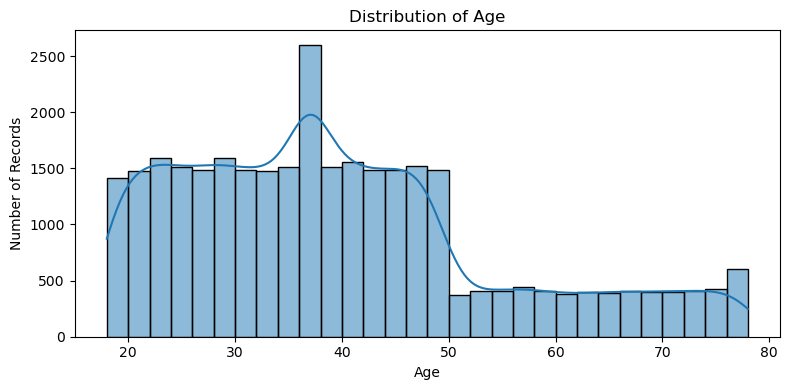

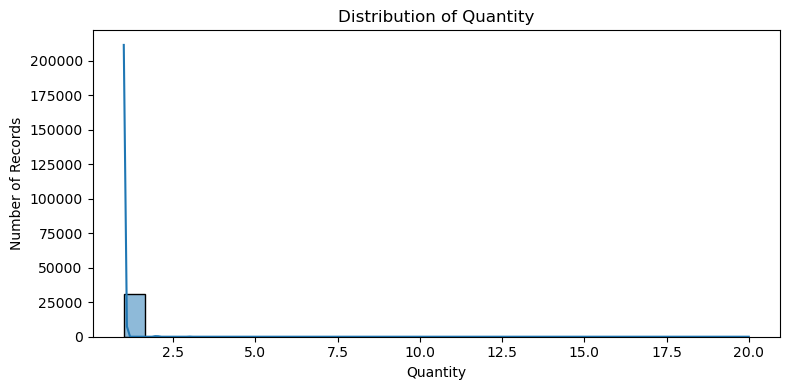

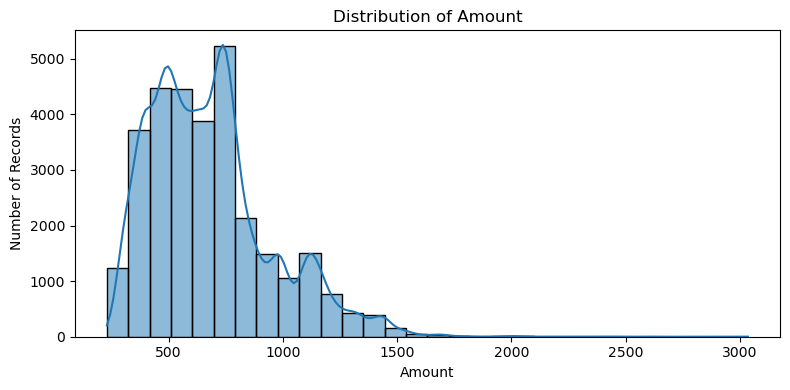

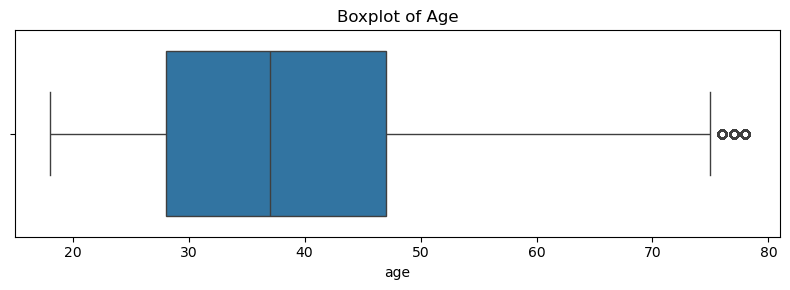

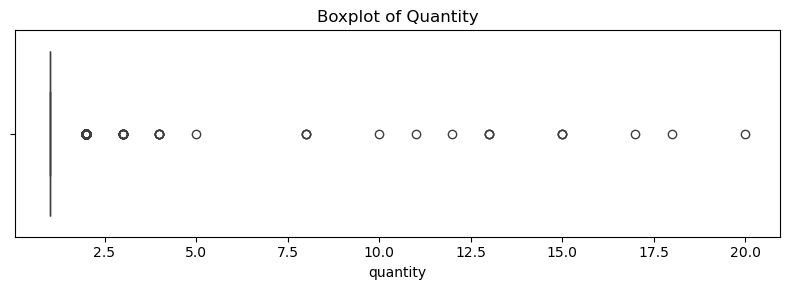

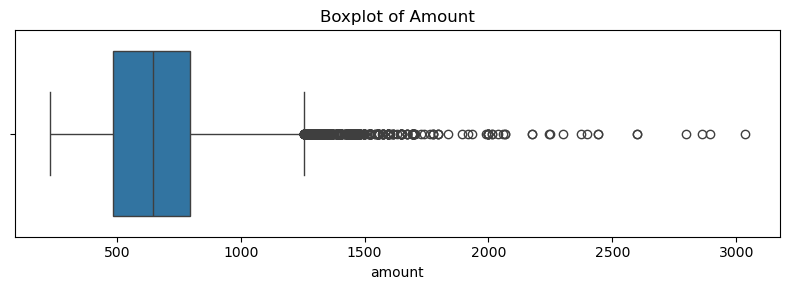

In [42]:

import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = ["age", "quantity", "amount"]

# Histograms: understand the shape of each distribution
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=data, x=col, bins=30, kde=True)
    plt.title(f"Distribution of {col.title()}")
    plt.xlabel(col.title())
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

# Boxplots: inspect spread and potential outliers
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=data[col])
    plt.title(f"Boxplot of {col.title()}")
    plt.tight_layout()
    plt.show()


## 2.Customer Analysis

**2.1-Customer Demographics**

**A.Gender Distribution**

In [46]:
# Gender-wise record count and percentage
gender_analysis = pd.DataFrame({
    "record_count": data["gender"].value_counts(),
    "percentage": (
        data["gender"].value_counts(normalize=True) * 100
    ).round(2)
})

display(gender_analysis)

,record_count,percentage
gender,,
Women,20813,67.04
Men,9159,29.50
Unknown,1075,3.46


In [ ]:
Observation: Women account for 20,813 records (67.04%), men account for 9,159 (29.50%), and unknown gender accounts for 1,075 (3.46%).

Interpretation: Women represent the largest share of recorded retail activity, but these are record percentages rather than unique-customer percentages.

Business Insight: Prioritize testing campaigns for the female customer segment, while running targeted experiments to grow engagement among male customers.

**B.Age Distribution**

In [48]:
# Summary statistics for age
display(data["age"].describe())

# Age-group count and percentage
age_analysis = pd.DataFrame({
    "record_count": data["age_group"].value_counts(),
    "percentage": (
        data["age_group"].value_counts(normalize=True) * 100
    ).round(2)
})

display(age_analysis)

count    31047.000000
mean        39.392985
std         14.844391
min         18.000000
25%         28.000000
50%         37.000000
75%         47.000000
max         78.000000
Name: age, dtype: float64

,record_count,percentage
age_group,,
Adult,15560,50.12
Teenager,9407,30.30
Senior,6080,19.58


In [ ]:
Observation: The average age is 39.39 years, the median is 37, and the middle 50% of ages fall between 28 and 47. Adults account for 50.12% of records, teenagers 30.30%, and seniors 19.58%.

Interpretation: Adults make up the largest age group in the dataset, followed by teenagers.

Business Insight: Prioritize product recommendations and marketing campaigns for adult customers, while maintaining separate offers for teenagers and seniors to compare engagement and purchasing outcomes.

**C.Visualize Demographics**

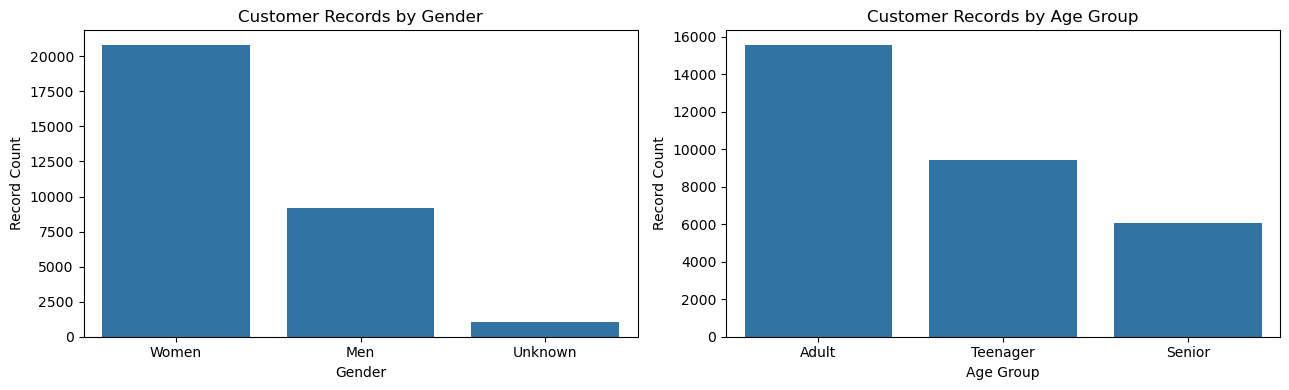

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=data, x="gender", ax=axes[0])
axes[0].set_title("Customer Records by Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Record Count")

sns.countplot(data=data, x="age_group", ax=axes[1])
axes[1].set_title("Customer Records by Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Record Count")

plt.tight_layout()
plt.show()


**2.1 Findings**
The demographic analysis of SwiftCart's 31,047 records shows that Women account for 67.04% of records, Men account for 29.50%, and Unknown accounts for 3.46%. This indicates that records associated with women form the largest share of the dataset.

The average recorded age is 39.39 years, and the median age is 37 years. The middle 50% of ages range from 28 to 47 years. Across the defined age groups, Adult represents the largest share at 50.12%, followed by Teenager at 30.30% and Senior at 19.58%.

These findings describe the demographic composition of SwiftCart's available records. The business can further investigate product preferences, sales channels, and recorded amounts across gender and age groups to support customer segmentation and marketing decisions.

**Limitation:** The results are based on record counts and should not be interpreted as unique-customer proportions unless the data is aggregated by customer ID.

**2.2-Customer Distribution**

**A.Customer ID Analysis**

In [108]:
print("Total records:", len(data))
print("Unique customer IDs:", data["customer_id"].nunique())
print("Missing customer IDs:", data["customer_id"].isna().sum())

# How many records are associated with each known customer ID?
customer_frequency = data["customer_id"].value_counts()

print("\nCustomer record frequency:")
display(customer_frequency.describe())

print("\nTop 10 customer IDs by record count:")
display(customer_frequency.head(10).to_frame("record_count"))

Total records: 31047
Unique customer IDs: 28394
Missing customer IDs: 41

Customer record frequency:


count     28394.0
mean     1.091991
std       0.37841
min           1.0
25%           1.0
50%           1.0
75%           1.0
max          12.0
Name: count, dtype: Float64


Top 10 customer IDs by record count:


,record_count
customer_id,
4984515,12
173977,11
3701762,9
2997706,8
4410167,7
561446,7
9984530,7
49070840,7
3363121,7


**Observation:** Most customer IDs appear only once, while a few IDs appear multiple times. Customer ID 4984515 has the highest frequency, with 12 records.

**Interpretation:** The dataset contains many customer IDs with a low record frequency. However, multiple records for the same ID do not automatically mean repeat purchases because the dataset may contain multiple records per order.

Business Insight: Use customer-level purchase history to identify genuine repeat buyers and create retention offers for customers who have purchased more than once.

**B.State-Wise Distribution**

In [114]:
state_analysis = (
    data.groupby("ship_state")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("record_count")
)

state_analysis["percentage"] = (
    state_analysis["record_count"] / len(data) * 100
).round(2)

display(state_analysis)

,record_count,percentage
ship_state,,
Maharashtra,4519,14.56
Karnataka,3988,12.85
Uttar Pradesh,2882,9.28
Tamil Nadu,2679,8.63
Telangana,2527,8.14
Delhi,1843,5.94
Kerala,1549,4.99
West Bengal,1425,4.59
Andhra Pradesh,1369,4.41


**Observation:** Maharashtra has the highest number of records (4,519; 14.56%), followed by Karnataka (3,988; 12.85%). Haryana has the lowest record count among these ten states.and overall least has ladkh

**Interpretation:** The recorded retail activity is concentrated more heavily in Maharashtra and Karnataka than in the other states shown.

**Business Insight:** These states may be useful starting points for examining product demand, delivery performance, and regional marketing opportunities. Record counts alone do not establish which states generate the highest revenue or profit.
Also Prioritize inventory availability and regional marketing tests in Maharashtra and Karnataka, where recorded activity is highest, while measuring the results by sales and delivery performance.

**C.City-wise Distribution**

In [77]:
city_analysis = (
    data.groupby("ship_city")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("record_count")
)

display(city_analysis)

,record_count
ship_city,
Bengaluru,2673
Hyderabad,1998
New Delhi,1684
Chennai,1468
Mumbai,1402
Pune,863
Kolkata,696
Lucknow,480
Gurugram,460


**Observation:** Bengaluru has the highest record count (2,673), followed by Hyderabad (1,998) and New Delhi (1,684). Noida has the lowest count among the ten cities listed (381).

**Interpretation:** The recorded activity is concentrated in a few major cities, particularly Bengaluru and Hyderabad.

Business Insight: Prioritize local promotions and product availability in Bengaluru and Hyderabad, and compare campaign performance before expanding to additional cities.



**2.3 Customer segments**

**A.Age group & Gender segments**

In [81]:
segment_analysis = (
    data.groupby(["age_group", "gender"], observed=True)
    .agg(
        record_count=("age", "size"),
        average_age=("age", "mean"),
        average_amount=("amount", "mean"),
        median_amount=("amount", "median"),
        total_recorded_amount=("amount", "sum")
    )
    .round(2)
    .sort_values("record_count", ascending=False)
)

display(segment_analysis)

,,record_count,average_age,average_amount,median_amount,total_recorded_amount
age_group,gender,,,,,
Adult,Women,10364,39.38,630.08,560.0,6530192
Teenager,Women,6333,24.11,623.69,549.0,3949851
Adult,Men,4627,39.54,798.26,743.0,3693548
Senior,Women,4116,63.09,630.95,563.0,2596997
Teenager,Men,2756,23.98,808.37,743.0,2227868
Senior,Men,1776,63.10,795.43,743.0,1412684
Adult,Unknown,569,39.29,700.49,650.0,398581
Teenager,Unknown,318,23.92,717.81,669.0,228265
Senior,Unknown,188,61.10,736.12,694.5,138391


**Observations:** Adult Women have the highest record count (10,364) and total recorded amount (₹6,530,192). However, average recorded amounts are higher for men in every age group: Adult Men ₹798.26, Teenager Men ₹808.37, and Senior Men ₹795.43.

**Interpretation:** Women contribute more total recorded amount because they have substantially more records, while men's average recorded amounts are higher.

**Business Insight:** Maintain marketing activity for Adult Women to support the largest existing segment, and test higher-value product recommendations for male customers, especially teenagers, to determine whether their higher average amount can translate into additional sales.




**B.B2B vs non-B2B segments**

In [84]:
b2b_segment = (
    data.groupby("b2b", observed=True)
    .agg(
        record_count=("b2b", "size"),
        average_amount=("amount", "mean"),
        median_amount=("amount", "median"),
        total_recorded_amount=("amount", "sum")
    )
    .round(2)
)

b2b_segment["record_percentage"] = (
    b2b_segment["record_count"] / len(data) * 100
).round(2)

display(b2b_segment)

,record_count,average_amount,median_amount,total_recorded_amount,record_percentage
b2b,,,,,
False,30861,682.09,646.0,21050056,99.4
True,186,679.15,669.5,126321,0.6


**Observation:** Non-B2B accounts for 30,861 records (99.4%) and ₹21,050,056 in recorded amount. B2B accounts for 186 records (0.6%) and ₹126,321. Average amounts are similar: ₹682.09 for non-B2B and ₹679.15 for B2B.

**Interpretation:** The recorded activity is overwhelmingly non-B2B. B2B is a small segment, with no clear advantage in average recorded amount.

**Business Insight:** Keep the main sales strategy focused on individual consumers, while testing a targeted B2B outreach campaign to determine whether business customers can become a meaningful additional sales segment.


**2.4 Customer purchasing behavior**

**A.purchasing behavior by gender**

In [88]:
gender_behavior = (
    data.groupby("gender", observed=True)
    .agg(
        record_count=("gender", "size"),
        average_quantity=("quantity", "mean"),
        average_amount=("amount", "mean"),
        median_amount=("amount", "median"),
        total_recorded_amount=("amount", "sum")
    )
    .round(2)
)

display(gender_behavior)

,record_count,average_quantity,average_amount,median_amount,total_recorded_amount
gender,,,,,
Men,9159,1.01,800.75,743.0,7334100
Unknown,1075,1.01,711.85,665.0,765237
Women,20813,1.01,628.31,560.0,13077040



**Observation:** Women contribute ₹13,077,040 in total recorded amount, while men have the highest average recorded amount at ₹800.75. Average quantity is approximately 1.01 across all gender groups.

**Interpretation:** Women lead in total recorded amount, whereas men's records have higher average amounts. Purchase quantities are similar across groups.

**Business Insight:** Use product recommendations suited to women's purchasing patterns to support overall sales, and test premium or higher-value products among men to build on their higher average recorded amount.

**B.Purchasing behavior by age group**

In [91]:
age_behavior = (
    data.groupby("age_group", observed=True)
    .agg(
        record_count=("age_group", "size"),
        average_quantity=("quantity", "mean"),
        average_amount=("amount", "mean"),
        median_amount=("amount", "median"),
        total_recorded_amount=("amount", "sum")
    )
    .round(2)
    .sort_values("total_recorded_amount", ascending=False)
)

display(age_behavior)

,record_count,average_quantity,average_amount,median_amount,total_recorded_amount
age_group,,,,,
Adult,15560,1.01,682.67,646.0,10622321
Teenager,9407,1.01,680.98,646.0,6405984
Senior,6080,1.01,682.25,646.0,4148072


Observation: Adults contribute the highest total recorded amount at ₹10,622,321. Average recorded amounts are similar across adults (₹682.67), teenagers (₹680.98), and seniors (₹682.25).

Interpretation: Adults contribute more total recorded amount largely because they account for more records, not because their average amount is substantially higher.

Business Insight: Prioritize adult customers for broad-reach campaigns, but differentiate offers by age group only where product preferences or campaign results show a meaningful difference.


**C.Order status by customer demographics**

In [94]:
status_analysis = pd.crosstab(
    data["age_group"],
    data["status"],
    normalize="index"
).mul(100).round(2)

display(status_analysis)

status,Cancelled,Delivered,Refunded,Returned
age_group,,,,
Adult,2.83,92.11,1.64,3.43
Senior,2.45,92.35,2.09,3.11
Teenager,2.71,92.42,1.44,3.43


Observation: Delivery rates exceed 92% for all age groups. Teenagers have the highest delivery percentage (92.42%), while adults have the highest cancellation percentage (2.83%). Return percentages are 3.43% for both adults and teenagers.

Interpretation: Order outcomes are broadly similar across age groups, with relatively small differences in cancellation and return percentages.

Business Insight: Maintain the existing delivery performance across all age groups and prioritize reducing cancellations among adults, while testing whether clearer product information or improved order communication can reduce returns among adults and teenagers.

**D.Sales channel by gender**

In [97]:
channel_gender = pd.crosstab(
    data["gender"],
    data["channel"],
    normalize="index"
).mul(100).round(2)

display(channel_gender)

channel,Ajio,Amazon,Flipkart,Meesho,Myntra,Nalli,Others
gender,,,,,,,
Men,6.15,36.27,21.54,4.17,22.90,4.83,4.15
Unknown,6.60,32.84,22.23,4.84,25.12,4.47,3.91
Women,6.23,35.27,21.58,4.63,23.48,4.78,4.03


**Observation:** Amazon is the leading channel for every gender group (32.84%–36.27%), followed by Flipkart (21.54%–22.23%) and Myntra (22.90%–25.12%).
                                              
**Interpretation:** Shopping-channel distribution is similar across gender groups, and Amazon leads in each.

Business Insight: Prioritize campaign testing and product availability on Amazon, while using Flipkart and Myntra as additional channels to reach customers and compare performance.

**2.5 Visulize customer purchasing behavior**

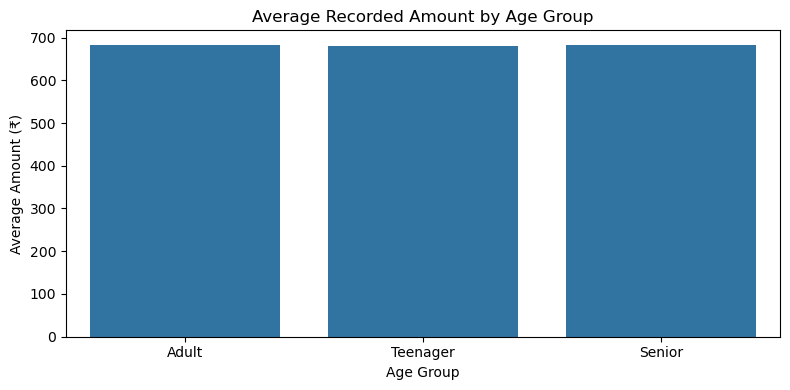

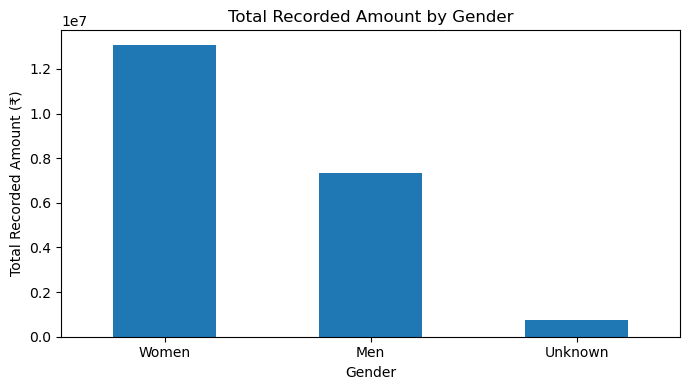

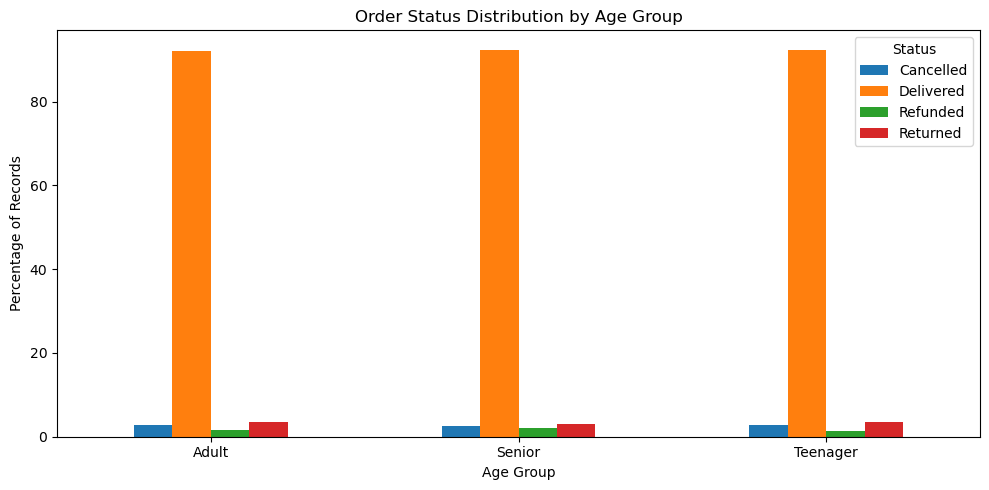

In [102]:

# Average recorded amount by age group
plt.figure(figsize=(8, 4))
sns.barplot(
    data=data,
    x="age_group",
    y="amount",
    estimator="mean",
    errorbar=None
)
plt.title("Average Recorded Amount by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Amount (₹)")
plt.tight_layout()
plt.show()

# Total recorded amount by gender
gender_totals = (
    data.groupby("gender")["amount"]
    .sum()
    .sort_values(ascending=False)
)

gender_totals.plot(kind="bar", figsize=(7, 4))
plt.title("Total Recorded Amount by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Recorded Amount (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Order-status distribution by age group
pd.crosstab(
    data["age_group"],
    data["status"],
    normalize="index"
).mul(100).plot(kind="bar", figsize=(10, 5))

plt.title("Order Status Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)
plt.legend(title="Status")
plt.tight_layout()
plt.show()


## 3.Product Analysis

**A. Product categories**

In [131]:
# A. Product category distribution
category_analysis = data.groupby("category").agg(
    record_count=("category", "size"),
    total_recorded_amount=("amount", "sum"),
    average_amount=("amount", "mean")
).sort_values("record_count", ascending=False)

print(category_analysis)

               record_count  total_recorded_amount  average_amount
category                                                          
Set                   12391               10507546      847.998225
Kurta                 10446                4959377      474.763259
Western Dress          4066                3148836      774.430890
Top                    2193                1186199      540.902417
Saree                  1380                1010471      732.225362
Ethnic Dress            264                 195256      739.606061
Blouse                  229                 140888      615.231441
Bottom                   78                  27804      356.461538


**Observation:** Sets have the highest record count (12,391) and total recorded amount (10,507,546), followed by Kurtas.
    
**Interpretation:** Sets and Kurtas dominate the recorded product activity.

Business Insight: Prioritize stock availability for Sets and Kurtas, especially Sets, and use their strong recorded performance to guide category-level inventory and promotional planning.

**B.Product size distribution**

In [134]:
# B. Product size distribution
print(data["size"].value_counts(dropna=False))

size
M       5485
L       5144
XL      4437
S       4176
XXL     4065
3XL     3347
XS      2503
Free    1408
6XL      208
5XL      161
4XL      113
Name: count, dtype: int64


**Observation:** M is the most common size (5,485 records), followed by L (5,144) and XL (4,437). Sizes 4XL, 5XL, and 6XL have the fewest records.

**Interpretation:** Recorded demand is concentrated in medium and large sizes.

Allocate inventory in line with observed size-level demand, keeping stronger availability for M, L, and XL while using sales and stockout data to determine suitable quantities for less frequently recorded sizes.


**C.Product demand by category**

In [137]:
# C. Product demand by category
print(data.groupby("category").agg(
    total_quantity=("quantity", "sum"),
    record_count=("category", "size")
).sort_values("total_quantity", ascending=False))

               total_quantity  record_count
category                                   
Set                     12522         12391
Kurta                   10630         10446
Western Dress            4084          4066
Top                      2217          2193
Saree                    1389          1380
Ethnic Dress              264           264
Blouse                    234           229
Bottom                     78            78


**Observation:** Sets have the highest total quantity (12,522), followed by Kurtas (10,630) and Western Dresses (4,084).

**Interpretation:** Sets and Kurtas lead in both record count and quantity.

Business Insight: Give Sets and Kurtas priority in replenishment planning, and use their demand patterns to guide purchasing decisions while avoiding excess inventory in lower-volume categories.

**D. Product distribution**

In [140]:
# D. Top 10 SKUs by record count
print(data["sku"].value_counts().head(10))

sku
JNE3797-KR-L       273
JNE3797-KR-M       232
JNE3797-KR-S       169
JNE3797-KR-XXL     150
JNE3797-KR-XL      149
JNE3797-KR-XXXL    140
JNE3405-KR-S       134
J0230-SKD-M        128
J0230-SKD-S        126
JNE3405-KR-L       114
Name: count, dtype: int64


**Observation:** SKU JNE3797-KR-L has the highest record count (273), followed by JNE3797-KR-M (232) and JNE3797-KR-S (169).

**Interpretation:** The JNE3797-KR SKU family appears frequently in the dataset.

Business Insight: Prioritize stock monitoring for the high-volume SKUs in the JNE3797-KR family, including size-specific replenishment based on actual sales and stock availability.

**E. Product performance**

In [143]:
# E. Product performance by category
print(data.groupby("category")["amount"].agg(
    ["count", "mean", "median", "sum"]
).sort_values("sum", ascending=False))

               count        mean  median       sum
category                                          
Set            12391  847.998225   788.0  10507546
Kurta          10446  474.763259   457.0   4959377
Western Dress   4066  774.430890   735.0   3148836
Top             2193  540.902417   522.0   1186199
Saree           1380  732.225362   666.0   1010471
Ethnic Dress     264  739.606061   837.0    195256
Blouse           229  615.231441   625.0    140888
Bottom            78  356.461538   345.0     27804


**Observation:** Sets have the highest average recorded amount (847.99), while Western Dresses average 774.43. Bottoms have the lowest average (356.46).

**Interpretation:** Sets combine high record volume with the highest average amount, making them the strongest category by total recorded amount.

Business Insight: Prioritize Sets when planning category promotions and inventory, and evaluate whether complementary-product offers can increase the value of Bottoms purchases. Avoid reducing a category's stock solely because its recorded amount is low; consider margins and demand before making that decision.

**Overall conclusion**
Sets and Kurtas lead in product volume and total recorded amount, while Sets also have the highest average recorded amount. Medium and large sizes are the most frequently recorded, and a small group of SKUs accounts for the highest individual record counts. These patterns can guide inventory planning and further product analysis.

## 4.Sales Analysis

**A.Overall sales pattern**

In [178]:
print("Total Recorded Amount:", data["amount"].sum())
print("Average Amount:", data["amount"].mean())
print("Median Amount:", data["amount"].median())
print("Minimum Amount:", data["amount"].min())
print("Maximum Amount:", data["amount"].max())
print("Total Records:", len(data))

Total Recorded Amount: 21176377
Average Amount: 682.0748220439978
Median Amount: 646.0
Minimum Amount: 229
Maximum Amount: 3036
Total Records: 31047


**Observation:** Total recorded amount is ₹21,176,377 across 31,047 records. Average amount is ₹682.07 and median is ₹646.

**Interpretation:** The average is slightly higher than the median, indicating some higher-value records.

Business Insight: Use the median amount of ₹646 as a benchmark for typical recorded spending, and test promotions designed to increase average purchase value without relying on a few high-value records.

**B.Sales distribution by month**

In [157]:
monthly_sales = data.groupby("month")["amount"].agg(
    record_count="count",
    total_recorded_amount="sum",
    average_amount="mean"
)

print(monthly_sales)

       record_count  total_recorded_amount  average_amount
month                                                     
Apr            2645                1801677      681.163327
Aug            2580                1782789      691.003488
Dec            2351                1598361      679.864313
Feb            2709                1847957      682.154670
Jan            2665                1795511      673.737711
Jul            2540                1743535      686.431102
Jun            2557                1721956      673.428236
Mar            2793                1909361      683.623702
May            2577                1768087      686.102833
Nov            2345                1591723      678.773134
Oct            2369                1627873      687.156184
Sep            2451                1664053      678.928193


**Observation:** March has the highest total recorded amount (₹1,909,361), while November has the lowest (₹1,591,723).

**Interpretation:** Recorded sales vary by month, with March performing best and November lowest.

Business Insight: Use March's performance as a benchmark for monthly sales planning, and test targeted promotions in November and December. Study August's higher average amount to see whether its product mix or purchasing patterns can be replicated in other months.

**C.High performing areas-State,City,Channel**

In [160]:
# State-wise sales
print(data.groupby("ship_state")["amount"].sum()
      .sort_values(ascending=False).head(10))

# City-wise sales
print(data.groupby("ship_city")["amount"].sum()
      .sort_values(ascending=False).head(10))

# Channel-wise sales
print(data.groupby("channel")["amount"].sum()
      .sort_values(ascending=False))

ship_state
Maharashtra       2990221
Karnataka         2646358
Uttar Pradesh     2104659
Telangana         1712439
Tamil Nadu        1678877
Delhi             1274750
Kerala            1008940
West Bengal        922444
Andhra Pradesh     918499
Haryana            813320
Name: amount, dtype: int64
ship_city
Bengaluru    1766657
Hyderabad    1370811
New Delhi    1162928
Chennai       922887
Mumbai        917625
Pune          569934
Kolkata       443378
Lucknow       362364
Gurugram      327542
Noida         264419
Name: amount, dtype: int64
channel
Amazon      7519933
Myntra      4941540
Flipkart    4573301
Ajio        1331427
Nalli       1015329
Meesho       927606
Others       867241
Name: amount, dtype: int64


**Observation:** Maharashtra leads state-wise recorded amount (₹2,990,221), Bengaluru leads city-wise (₹1,766,657), and Amazon leads channels (₹7,519,933).

**Interpretation:** These are the strongest-performing areas by total recorded amount among the results provided.

Business Insight: Prioritize campaign and inventory planning for Maharashtra, Bengaluru, and Amazon, while measuring conversion, fulfillment, and profitability before increasing investment.

**D.Low performing areas**

In [163]:
# 10 states with the lowest recorded amounts
print(data.groupby("ship_state")["amount"].sum()
      .sort_values().head(10))

# 10 cities with the lowest recorded amounts
print(data.groupby("ship_city")["amount"].sum()
      .sort_values().head(10))

# Channel-wise recorded amounts, lowest first
print(data.groupby("channel")["amount"].sum()
      .sort_values())

ship_state
Mizoram              12182
Ladakh               14148
Dadra And Nagar      14980
Meghalaya            25988
Tripura              30961
Arunachal Pradesh    36840
Nagaland             43510
Puducherry           48553
Andaman & Nicobar    51970
Sikkim               54916
Name: amount, dtype: int64
ship_city
Vrindavan     {Mathura}                   301
Elgaid                                    301
Perambra                                  307
Multai                                    319
Dharmasthala                              329
Reasi                                     339
Ns Rd 10, Jvpds, Vile Parle (W) Mumbai    348
Industrial Park Naidupet                  353
Deulia                                    358
Chirkunda                                 362
Name: amount, dtype: int64
channel
Others       867241
Meesho       927606
Nalli       1015329
Ajio        1331427
Flipkart    4573301
Myntra      4941540
Amazon      7519933
Name: amount, dtype: int64


**Observation:** Mizoram has the lowest recorded amount among the listed states (₹12,182), the listed city with the lowest amount is Vrindavan {Mathura} (₹301), and Others is the lowest channel (₹867,241).

**Interpretation:** Recorded amounts differ considerably across locations and channels.

Business Insight: Test small, targeted promotions in selected low-volume locations and evaluate the results before expanding investment. Review the cost and performance of the Others channel before deciding whether to change its allocation.

**E.Variation in sales**

In [166]:
# Monthly sales variation
monthly_variation = data.groupby("month")["amount"].sum()

print("Monthly Sales:")
print(monthly_variation)

print("Sales Standard Deviation:", data["amount"].std())
print("Sales Variance:", data["amount"].var())
print("Sales 25th Percentile:", data["amount"].quantile(0.25))
print("Sales 75th Percentile:", data["amount"].quantile(0.75))

Monthly Sales:
month
Apr    1801677
Aug    1782789
Dec    1598361
Feb    1847957
Jan    1795511
Jul    1743535
Jun    1721956
Mar    1909361
May    1768087
Nov    1591723
Oct    1627873
Sep    1664053
Name: amount, dtype: int64
Sales Standard Deviation: 268.58217349679825
Sales Variance: 72136.38392026424
Sales 25th Percentile: 486.0
Sales 75th Percentile: 794.0


**Observation:** Monthly recorded amounts range from ₹1,591,723 to ₹1,909,361. The amount standard deviation is ₹268.58, and the 25th and 75th percentiles are ₹486 and ₹794.

**Interpretation:** Individual record amounts vary, while monthly totals remain within a relatively narrow range compared with the overall totals.

Business Insight: Use the ₹486–₹794 middle range to evaluate offers aimed at typical purchases, and monitor monthly totals against the March benchmark to identify when sales campaigns may need adjustment.

## 5. Order Analysis

**A.Order patterns**

In [7]:
print("Total Records:", len(data))
print("Unique Order IDs:", data["order_id"].nunique())
print("Missing Order IDs:", data["order_id"].isna().sum())

print("\nRecords per Order:")
print(data.groupby("order_id").size().describe())

Total Records: 31047
Unique Order IDs: 27555
Missing Order IDs: 1080

Records per Order:
count    27555.000000
mean         1.087534
std          0.368463
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         12.000000
dtype: float64


**Observation:** The dataset contains 31,047 records, 27,555 unique Order IDs, and 1,080 missing Order IDs. Most identified orders have one record, while the maximum is 12 records per order.
    
**Interpretation:** Most orders appear as single records, but some orders contain multiple records. Missing Order IDs limit the accuracy of order-level analysis.

Business Insight: Use the order-level distribution to identify single-item versus multi-item purchasing patterns and design relevant product-bundle offers to increase items purchased per order.


**B.Order status**

In [10]:
status_analysis = data["status"].value_counts().to_frame("record_count")

status_analysis["percentage"] = (
    status_analysis["record_count"] / len(data) * 100
).round(2)

print(status_analysis)

           record_count  percentage
status                             
Delivered         28641       92.25
Returned           1045        3.37
Cancelled           844        2.72
Refunded            517        1.67


**Observation:** Delivered records account for 92.25%, followed by Returned (3.37%), Cancelled (2.72%), and Refunded (1.67%).

**Interpretation:** Most records have a successful delivery status. Returns, cancellations, and refunds account for a smaller share.

Business Insight: Prioritize delivery success while setting measurable targets to reduce returns, cancellations, and refunds. Track each outcome separately to identify which improvement has the greatest impact


**C.Quantity patterns**

In [13]:
print("Total Quantity:", data["quantity"].sum())
print("Average Quantity:", data["quantity"].mean())
print("Median Quantity:", data["quantity"].median())
print("Minimum Quantity:", data["quantity"].min())
print("Maximum Quantity:", data["quantity"].max())

print("\nQuantity Frequency:")
print(data["quantity"].value_counts().sort_index())

Total Quantity: 31418
Average Quantity: 1.0119496247624569
Median Quantity: 1.0
Minimum Quantity: 1
Maximum Quantity: 20

Quantity Frequency:
quantity
1     30876
2       130
3        19
4         6
5         1
8         3
10        1
11        1
12        1
13        3
15        3
17        1
18        1
20        1
Name: count, dtype: int64


**Observation:** Total quantity is 31,418, with an average of 1.01 and a median of 1. Quantity ranges from 1 to 20, and 30,876 records have quantity 1.

**Interpretation:** Single-quantity purchases dominate the dataset. A few records have unusually high quantities compared with the typical purchase.

Business Insight: Test complementary-product recommendations and quantity-based offers to encourage multi-item purchases, and compare the resulting average quantity and recorded amount against the current baseline.

**D.Order distribution**

In [16]:
# Order records by month
print(data.groupby("month")["order_id"].count().sort_values(ascending=False))

# Order records by sales channel
print(data.groupby("channel")["order_id"].count().sort_values(ascending=False))

# Order records by state — top 10
print(data.groupby("ship_state")["order_id"].count()
      .sort_values(ascending=False).head(10))

month
Mar    2696
Feb    2621
Jan    2571
Apr    2549
Aug    2503
May    2485
Jun    2460
Jul    2453
Sep    2362
Dec    2276
Oct    2273
Nov    2265
Name: order_id, dtype: int64
channel
Amazon      10614
Myntra       7013
Flipkart     6470
Ajio         1871
Nalli        1427
Meesho       1353
Others       1219
Name: order_id, dtype: int64
ship_state
Maharashtra       4363
Karnataka         3843
Uttar Pradesh     2778
Tamil Nadu        2594
Telangana         2427
Delhi             1783
Kerala            1498
West Bengal       1373
Andhra Pradesh    1327
Haryana           1078
Name: order_id, dtype: int64


**Observation:** March has the highest monthly count (2,696), while November has the lowest (2,265). Amazon leads the channels with 10,614 records, followed by Myntra (7,013) and Flipkart (6,470). Maharashtra leads state distribution with 4,363 records.

**Interpretation:** Record distribution varies by month, sales channel, and state. Amazon is the leading channel, and Maharashtra contributes the largest state-level count.

Business Insight: Prioritize operational capacity and inventory planning for peak-volume periods and high-volume channels and states, while monitoring fulfillment performance as volume changes.

**E.Successful and Unsuccessful order patterns**

In [19]:
# Status counts by channel
print(pd.crosstab(data["channel"], data["status"]))

# Status counts by month
print(pd.crosstab(data["month"], data["status"]))

# Status counts by quantity
print(pd.crosstab(data["quantity"], data["status"]))

status    Cancelled  Delivered  Refunded  Returned
channel                                           
Ajio             54       1793        24        60
Amazon          308      10124       201       383
Flipkart        188       6173       113       229
Meesho           38       1288        25        47
Myntra          188       6713       116       237
Nalli            34       1375        22        53
Others           34       1175        16        36
status  Cancelled  Delivered  Refunded  Returned
month                                           
Apr            74       2455        41        75
Aug            60       2385        40        95
Dec            50       2136        34       131
Feb            79       2507        63        60
Jan            70       2502        42        51
Jul            60       2339        24       117
Jun            74       2339        65        79
Mar            83       2629        21        60
May            78       2409        23        67
No

**Observation:** Amazon has the highest number of delivered records (10,124), but also the highest counts of cancellations (308), refunds (201), and returns (383). December has the highest return count (131), followed by October (126). Most quantity-1 records are delivered (28,478).

**Interpretation:** Amazon's higher unsuccessful counts occur alongside its much larger volume, so counts alone do not establish that it has a worse failure rate. Returns are more frequent in December and October than in several other months. Most transactions involve quantity 1.

Business Insight: Compare unsuccessful-order rates across channels before reallocating channel investment. Prioritize return-reduction initiatives for October and December, and evaluate whether product information, sizing guidance, or fulfillment improvements can reduce returned orders.
                

## 6. Time-Based Analysis

**A.Date range and Data completeness**

In [30]:
data["date"] = pd.to_datetime(data["date"], errors="coerce")

print("Earliest Date:", data["date"].min())
print("Latest Date:", data["date"].max())
print("Missing Dates:", data["date"].isna().sum())
print("Available Months:", data["month"].nunique())

Earliest Date: 2022-01-04 00:00:00
Latest Date: 2022-12-06 00:00:00
Missing Dates: 488
Available Months: 12


**Observation:** The dataset covers January 4, 2022, to December 6, 2022. There are 488 missing dates, and all 12 months are represented.

**Interpretation:** The dataset covers most of 2022, but missing dates may affect the accuracy of time-based analysis.

**Business Insight:** Business Insight: Base monthly planning on the available monthly results, and avoid making daily staffing or promotion decisions from this dataset until the daily coverage is reliable.

**B. Monthly sales activity**

In [33]:
monthly_sales = data.groupby("month").agg(
    record_count=("amount", "count"),
    total_recorded_amount=("amount", "sum"),
    average_amount=("amount", "mean")
).round(2)

print(monthly_sales)

       record_count  total_recorded_amount  average_amount
month                                                     
Apr            2645                1801677          681.16
Aug            2580                1782789          691.00
Dec            2351                1598361          679.86
Feb            2709                1847957          682.15
Jan            2665                1795511          673.74
Jul            2540                1743535          686.43
Jun            2557                1721956          673.43
Mar            2793                1909361          683.62
May            2577                1768087          686.10
Nov            2345                1591723          678.77
Oct            2369                1627873          687.16
Sep            2451                1664053          678.93


**Observation:** March has the highest recorded amount (₹1,909,361) and the highest record count (2,793). November has the lowest recorded amount (₹1,591,723), while December has the lowest record count (2,351). August has the highest average recorded amount (₹691.00).

**Interpretation:** March has the strongest overall recorded activity, while November and December are comparatively weaker. August has a higher average amount per record but not the highest total.

**Business Insight:** Use March's performance as a benchmark for monthly sales targets and test focused promotions in November and December. Examine August's product mix to identify opportunities to increase average recorded amount in other months.

**C. Daily activity trends**

In [36]:
daily_activity = data.groupby("date").agg(
    record_count=("order_id", "count"),
    total_recorded_amount=("amount", "sum")
)

print(daily_activity.describe())
print("\nTop 10 Days by Recorded Amount:")
print(daily_activity.sort_values(
    "total_recorded_amount", ascending=False
).head(10))

       record_count  total_recorded_amount
count     36.000000              36.000000
mean     819.388889          579067.361111
std      118.181767           81637.879777
min      641.000000          446201.000000
25%      744.750000          520326.250000
50%      799.500000          571713.000000
75%      863.000000          617899.750000
max     1122.000000          766936.000000

Top 10 Days by Recorded Amount:
            record_count  total_recorded_amount
date                                           
2022-03-05          1094                 766936
2022-02-05          1122                 763250
2022-04-05          1016                 720320
2022-01-05          1027                 704576
2022-10-04           975                 699307
2022-03-04           948                 685392
2022-08-04           895                 638451
2022-07-05           862                 626837
2022-05-04           866                 622690
2022-09-04           853                 616303


**Observation:** Only 36 distinct dates appear in the daily summary. March 5 has the highest recorded amount (₹766,936), while February 5 has the highest record count (1,122).

**Interpretation:** Some dates have much higher recorded activity, but the limited number of dates means the output may not represent a complete daily trend.

**Business Insight:** Use the highest-activity dates as starting points for evaluating campaign and product performance, but do not build a daily promotional calendar from this result alone.

**D.Customer activity over time**

In [39]:
customer_activity = data.groupby("month").agg(
    unique_customers=("customer_id", "nunique"),
    record_count=("customer_id", "count")
)

print(customer_activity)

       unique_customers  record_count
month                                
Apr                2459          2642
Aug                2383          2576
Dec                2159          2347
Feb                2485          2707
Jan                2437          2661
Jul                2316          2537
Jun                2349          2551
Mar                2586          2790
May                2373          2574
Nov                2187          2341
Oct                2191          2366
Sep                2257          2450


**Observation:** March has the highest unique customer count (2,586), while December has the lowest (2,159). November has 2,187 unique customers, and March also has the highest customer-linked record count (2,790).

**Interpretation:** Customer activity is strongest in March and lower in November and December.

**Business Insight:** Plan targeted customer engagement campaigns during November and December to encourage repeat purchases, and compare customer activity before and after the campaigns to assess their effectiveness.

**E.Order behavior over time**

In [42]:
monthly_orders = data.groupby("month").agg(
    order_id_count=("order_id", "count"),
    delivered=("status", lambda x: (x == "Delivered").sum()),
    returned=("status", lambda x: (x == "Returned").sum()),
    cancelled=("status", lambda x: (x == "Cancelled").sum()),
    refunded=("status", lambda x: (x == "Refunded").sum())
)

print(monthly_orders)

       order_id_count  delivered  returned  cancelled  refunded
month                                                          
Apr              2549       2455        75         74        41
Aug              2503       2385        95         60        40
Dec              2276       2136       131         50        34
Feb              2621       2507        60         79        63
Jan              2571       2502        51         70        42
Jul              2453       2339       117         60        24
Jun              2460       2339        79         74        65
Mar              2696       2629        60         83        21
May              2485       2409        67         78        23
Nov              2265       2105        89         81        70
Oct              2273       2123       126         72        48
Sep              2362       2284        75         54        38


**Observation:** March has the highest delivered count (2,629). December has the highest returned count (131), followed by October (126). November has the highest refunded count (70), while March has the lowest refunded count (21).

**Interpretation:** Delivered activity is strongest in March, while returns peak in December and refunds peak in November.

**Business Insight:** Prioritize return-reduction measures during October and December and refund-reduction measures during November. Track the monthly return and refund rates—not only the counts—to determine whether these periods actually have worse outcomes relative to order volume.

## Group-based analysis

**A.Category-wise performance**

In [51]:
category_analysis = data.groupby("category").agg(
    record_count=("category", "count"),
    total_quantity=("quantity", "sum"),
    total_amount=("amount", "sum"),
    average_amount=("amount", "mean")
).round(2)

category_analysis.sort_values(
    by="total_amount",
    ascending=False
)

,record_count,total_quantity,total_amount,average_amount
category,,,,
Set,12391,12522,10507546,848.00
Kurta,10446,10630,4959377,474.76
Western Dress,4066,4084,3148836,774.43
Top,2193,2217,1186199,540.90
Saree,1380,1389,1010471,732.23
Ethnic Dress,264,264,195256,739.61
Blouse,229,234,140888,615.23
Bottom,78,78,27804,356.46


**1. Observation:** Set category has the highest total recorded amount of ₹1,05,07,546 with 12,391 records. Kurta has 10,446 records and ₹49,59,377, while Western Dress has the third-highest recorded amount of ₹31,48,836. Bottom has the lowest recorded amount of ₹27,804.

**2. Interpretation:** Sets are the strongest category by recorded amount and record count. Kurtas also have high demand, while Western Dresses generate a relatively high amount from fewer records than Sets and Kurtas.

**3. Business Insight:** The business should prioritize stock availability for Sets and Kurtas, while testing targeted promotions for Western Dresses to increase sales. Bottom inventory can be kept proportionate to its observed demand.

**B. Gender-wise Performance**

In [53]:
gender_analysis = data.groupby("gender").agg(
    record_count=("gender", "count"),
    total_quantity=("quantity", "sum"),
    total_amount=("amount", "sum"),
    average_amount=("amount", "mean")
).round(2)

gender_analysis.sort_values(
    by="total_amount",
    ascending=False
)

,record_count,total_quantity,total_amount,average_amount
gender,,,,
Women,20813,21096,13077040,628.31
Men,9159,9237,7334100,800.75
Unknown,1075,1085,765237,711.85


**1.Observation:** Women account for 20,813 records and ₹1,30,77,040 in recorded amount. Men account for 9,159 records and ₹73,34,100. Men's average amount is ₹800.75, compared with ₹628.31 for Women.

**2. Interpretation:** Women contribute the largest overall recorded amount because they account for more records. Men have a higher average recorded amount per record.

**3. Business Insight:** The business should continue targeting women with relevant product collections and promotions, while testing bundles or premium product recommendations for men to encourage higher-value purchases.

In [ ]:
C. Age Group-wise Performance

In [56]:
age_group_analysis = data.groupby("age_group").agg(
    record_count=("age_group", "count"),
    total_quantity=("quantity", "sum"),
    total_amount=("amount", "sum"),
    average_amount=("amount", "mean")
).round(2)

age_group_analysis.sort_values(
    by="total_amount",
    ascending=False
)

,record_count,total_quantity,total_amount,average_amount
age_group,,,,
Adult,15560,15756,10622321,682.67
Teenager,9407,9511,6405984,680.98
Senior,6080,6151,4148072,682.25


**Observation:** Adults have the highest record count (15,560) and total recorded amount (₹1,06,22,321).
Teenagers have 9,407 records and a total recorded amount of ₹64,05,984.
Seniors have 6,080 records and a total recorded amount of ₹41,48,072.
The average amount per record is similar across all three groups, around ₹681–₹683.

**Interpretation:** Adults contribute the highest total recorded amount mainly because they account for the largest number of records. However, the average amount per record is almost the same across all age groups, so no group clearly stands out in average spending.

**Business Insight:** The business should prioritize reaching adult customers because they represent the largest group in this dataset. It can test targeted promotions for teenagers and seniors to increase their purchase frequency, then compare campaign results before expanding those promotions. 

In [ ]:
D. Sales Channel-wise Performance

In [58]:
channel_analysis = data.groupby("channel").agg(
    record_count=("channel", "count"),
    total_quantity=("quantity", "sum"),
    total_amount=("amount", "sum"),
    average_amount=("amount", "mean")
).round(2)

channel_analysis.sort_values(
    by="total_amount",
    ascending=False
)

,record_count,total_quantity,total_amount,average_amount
channel,,,,
Amazon,11016,11141,7519933,682.64
Myntra,7254,7373,4941540,681.22
Flipkart,6703,6764,4573301,682.28
Ajio,1931,1965,1331427,689.50
Nalli,1484,1490,1015329,684.18
Meesho,1398,1405,927606,663.52
Others,1261,1280,867241,687.74


**1. Observation:** Amazon has the highest record count (11,016) and recorded amount (₹75,19,933). Myntra follows with ₹49,41,540, and Flipkart records ₹45,73,301. Meesho has the lowest average amount at ₹663.52.

**2. Interpretation:** Amazon is the largest sales channel in this dataset by record count and recorded amount. Myntra and Flipkart are also important channels. Average amounts across channels are relatively similar.

**3. Business Insight:** The business should prioritize product availability and promotional planning on Amazon while maintaining strong listings on Myntra and Flipkart. It can test channel-specific offers on Meesho and compare results before increasing promotional spending.

**E. State-wise Performance**

In [60]:
state_analysis = data.groupby("ship_state").agg(
    record_count=("ship_state", "count"),
    total_quantity=("quantity", "sum"),
    total_amount=("amount", "sum"),
    average_amount=("amount", "mean")
).round(2)

state_analysis.sort_values(
    by="total_amount",
    ascending=False
).head(10)

,record_count,total_quantity,total_amount,average_amount
ship_state,,,,
Maharashtra,4519,4534,2990221,661.70
Karnataka,3988,4047,2646358,663.58
Uttar Pradesh,2882,2927,2104659,730.28
Telangana,2527,2555,1712439,677.66
Tamil Nadu,2679,2721,1678877,626.68
Delhi,1843,1853,1274750,691.67
Kerala,1549,1573,1008940,651.35
West Bengal,1425,1434,922444,647.33
Andhra Pradesh,1369,1408,918499,670.93


**1. Observation:** Maharashtra has the highest record count (4,519) and recorded amount (₹29,90,221). Karnataka follows with ₹26,46,358. Uttar Pradesh has ₹21,04,659 and an average amount of ₹730.28, the highest among the ten states shown.

**2. Interpretation:** Maharashtra and Karnataka are the largest markets among the states shown by recorded amount. Uttar Pradesh has a higher average amount per record, suggesting potential for higher-value sales.

**3. Business Insight:** The business should protect product availability and maintain effective promotions in Maharashtra and Karnataka. It should test targeted campaigns for Uttar Pradesh to see whether its higher average amount can translate into additional sales.

**F. Order Status-wise Performance**

In [62]:
status_analysis = data.groupby("status").agg(
    record_count=("status", "count"),
    total_quantity=("quantity", "sum"),
    total_amount=("amount", "sum"),
    average_amount=("amount", "mean")
).round(2)

status_analysis.sort_values(
    by="record_count",
    ascending=False
)

,record_count,total_quantity,total_amount,average_amount
status,,,,
Delivered,28641,28996,19710544,688.19
Returned,1045,1050,719147,688.18
Cancelled,844,851,481844,570.91
Refunded,517,521,264842,512.27


1. **Observation:** Delivered records account for 28,641 records and ₹1,97,10,544 in recorded amount. Returned records total 1,045, cancelled records total 844, and refunded records total 517. Cancelled and refunded records have lower average amounts than delivered records.

2. **Interpretation:** Most records are marked Delivered. Returns, cancellations, and refunds represent unsuccessful or reversed order outcomes that may affect customer experience and business performance. However, these figures alone do not establish the causes of those outcomes.

3. **Business Insight:** The business should investigate the reasons for returns, cancellations, and refunds, then prioritize corrective actions such as clearer product descriptions, more accurate size information, and delivery communication where the evidence supports them. It should track the status rates over time to evaluate improvement.

## Pivot Table Analysis

**1. Category-level Patterns**

**Purpose: Compare product categories by total quantity and recorded amount.**

In [58]:
category_pivot = data.pivot_table(
    index="category",
    values=["quantity", "amount"],
    aggfunc={
        "quantity": "sum",
        "amount": "sum"
    },
    fill_value=0
).sort_values(by="amount", ascending=False)

category_pivot

,amount,quantity
category,,
Set,10507546,12522
Kurta,4959377,10630
Western Dress,3148836,4084
Top,1186199,2217
Saree,1010471,1389
Ethnic Dress,195256,264
Blouse,140888,234
Bottom,27804,78


**Observation:** Sets contribute the highest recorded amount (₹1.05 crore), followed by Kurtas (₹49.59 lakh). Bottoms contribute the lowest amount.

**Business Insight:** Prioritize stock availability for Sets and Kurtas, and use targeted promotions to improve sales of lower-performing categories.

**2. Customer-level Patterns**

**Purpose: Compare recorded amounts across age groups and genders.**

In [26]:
customer_pivot = data.pivot_table(
    index="age_group",
    columns="gender",
    values="amount"
    aggfunc="sum",
    fill_value=0
)

customer_pivot

gender,Men,Unknown,Women
age_group,,,
Adult,3693548,398581,6530192
Senior,1412684,138391,2596997
Teenager,2227868,228265,3949851


**Observation:** Adult Women contribute the highest recorded amount (₹65.30 lakh), followed by Teenager Women (₹39.50 lakh).

**Business Insight:** Prioritize marketing to Adult Women and test targeted campaigns for Teenager Women to increase sales.

**3. Sales Patterns**

**Purpose: Compare monthly recorded amounts and quantities.**

In [29]:
sales_pivot = data.pivot_table(
    index="month",
    values=["amount", "quantity"],
    aggfunc={
        "amount": "sum",
        "quantity": "sum"
    },
    fill_value=0
)

sales_pivot

,amount,quantity
month,,
Apr,1801677,2681
Aug,1782789,2601
Dec,1598361,2357
Feb,1847957,2743
Jan,1795511,2680
Jul,1743535,2553
Jun,1721956,2600
Mar,1909361,2845
May,1768087,2614


**Observation:** March has the highest recorded amount (₹19.09 lakh), while November has the lowest (₹15.92 lakh).

**Business Insight:** Increase stock availability and promotions ahead of high-performing periods like March, and test targeted offers during lower-performing months such as November and December.

**4. Order Patterns**

**Purpose: Compare monthly records by order status, including Delivered, Returned, Cancelled, and Refunded.**

In [32]:
order_pivot = data.pivot_table(
    index="month",
    columns="status",
    values="order_id",
    aggfunc="count",
    fill_value=0
)

order_pivot

status,Cancelled,Delivered,Refunded,Returned
month,,,,
Apr,72,2365,38,74
Aug,56,2316,40,91
Dec,50,2068,34,124
Feb,77,2428,58,58
Jan,68,2414,40,49
Jul,60,2258,23,112
Jun,72,2249,62,77
Mar,77,2541,20,58
May,75,2322,23,65


**Observation:** December has the highest returns (124), while November has the highest cancellations (80) and refunds (68).

**Business Insight:** Investigate return reasons during December and review cancellation and refund causes in November to reduce unsuccessful orders.

**5. Geographic Patterns**

**Purpose: Identify states contributing the highest recorded amounts and quantities.**

In [35]:
geographic_pivot = data.pivot_table(
    index="ship_state",
    values=["amount", "quantity"],
    aggfunc={
        "amount": "sum",
        "quantity": "sum"
    },
    fill_value=0
).sort_values(by="amount", ascending=False)

geographic_pivot.head(10)

,amount,quantity
ship_state,,
Maharashtra,2990221,4534
Karnataka,2646358,4047
Uttar Pradesh,2104659,2927
Telangana,1712439,2555
Tamil Nadu,1678877,2721
Delhi,1274750,1853
Kerala,1008940,1573
West Bengal,922444,1434
Andhra Pradesh,918499,1408


**Observation:** Maharashtra has the highest recorded amount (₹29.90 lakh), followed by Karnataka (₹26.46 lakh). Haryana has the lowest among the ten states shown.

**Business Insight:** Prioritize inventory and marketing in Maharashtra and Karnataka, while testing targeted promotions in lower-performing states to grow sales.

**6. Channel-related Patterns**

**Purpose: Compare order-status records across sales channels to identify where returns, cancellations, and refunds are concentrated.**

In [38]:
channel_pivot = data.pivot_table(
    index="channel",
    columns="status",
    values="order_id",
    aggfunc="count",
    fill_value=0
)

channel_pivot

status,Cancelled,Delivered,Refunded,Returned
channel,,,,
Ajio,51,1737,23,60
Amazon,299,9752,192,371
Flipkart,177,5972,106,215
Meesho,37,1246,25,45
Myntra,185,6487,111,230
Nalli,31,1322,22,52
Others,33,1134,16,36


**Observation:** Amazon has the highest number of delivered records (9,752), but also the highest returns (371) and cancellations (299).

**Business Insight:** Prioritize Amazon’s sales while investigating its return and cancellation reasons; apply corrective actions to reduce unsuccessful orders without affecting sales.

## 9.Cross tab-Analysis

**1. Category Distribution**


In [60]:
pd.crosstab(data["category"], data["size"])

size,3XL,4XL,5XL,6XL,Free,L,M,S,XL,XS,XXL
category,,,,,,,,,,,
Blouse,0,0,0,0,28,53,43,37,33,1,34
Bottom,13,0,0,0,0,13,7,11,13,4,17
Ethnic Dress,39,0,0,0,0,50,47,39,40,18,31
Kurta,1209,102,146,192,0,1874,1821,1280,1646,616,1560
Saree,0,0,0,0,1380,0,0,0,0,0,0
Set,1326,11,15,16,0,2018,2477,1979,1745,1289,1515
Top,223,0,0,0,0,356,377,285,374,231,347
Western Dress,537,0,0,0,0,780,713,545,586,344,561


**Observation:** Sets and Kurtas have the widest size distribution, with M and L among their most frequent sizes. All Saree records use Free size.

**Business Insight:** Prioritize M and L stock for Sets and Kurtas, and maintain Free-size availability for Sarees based on demand.

**2. Customer Characteristics**

In [62]:
pd.crosstab(data["gender"], data["b2b"])

b2b,False,True
gender,,
Men,9100,59
Unknown,1067,8
Women,20694,119


**Observation:** Women have the highest record counts in both non-B2B (20,694) and B2B (119) segments.

**Business Insight:** Focus consumer marketing on women, while exploring targeted business offers to grow the small B2B segment.

**3. Order Status Patterns**

In [65]:
pd.crosstab(data["status"], data["b2b"])

b2b,False,True
status,,
Cancelled,840,4
Delivered,28464,177
Refunded,514,3
Returned,1043,2


**Observation:** Delivered records dominate both non-B2B (28,464) and B2B (177) segments. B2B has very few returns (2) and cancellations (4).

**Business Insight:** Maintain service quality for both segments and explore expanding B2B sales while monitoring order outcomes.

**4. Channel Patterns**

In [67]:
pd.crosstab(data["channel"], data["gender"])

gender,Men,Unknown,Women
channel,,,
Ajio,563,71,1297
Amazon,3322,353,7341
Flipkart,1973,239,4491
Meesho,382,52,964
Myntra,2097,270,4887
Nalli,442,48,994
Others,380,42,839


**Observation:** Women have the highest record counts across every sales channel. Amazon has the most women’s records (7,341), followed by Myntra (4,887) and Flipkart (4,491).

**Business Insight:** Target women-focused product promotions across major channels, prioritizing Amazon, Myntra, and Flipkart to reach the largest customer segment.

**5. Geographic Patterns**

In [72]:
pd.crosstab(data["ship_state"], data["channel"]).head(10)

channel,Ajio,Amazon,Flipkart,Meesho,Myntra,Nalli,Others
ship_state,,,,,,,
Andaman & Nicobar,8,24,18,2,11,7,2
Andhra Pradesh,85,474,289,60,334,62,65
Arunachal Pradesh,4,17,11,4,9,2,2
Assam,41,168,117,13,98,21,21
Bihar,42,187,141,20,146,25,20
Chandigarh,3,36,18,7,22,4,2
Chhattisgarh,18,76,53,14,61,13,11
Dadra And Nagar,0,11,4,3,3,0,0
Delhi,100,633,439,75,435,92,69


**Observation:** Amazon has the highest record counts across the states shown, including Delhi (633) and Andhra Pradesh (474).

**Business Insight:** Prioritize Amazon channel availability in these markets and use regional promotions to grow sales through other channels.

## 10.Relationship Analysis

**1. Numerical vs Numerical**

**Business question: Is a higher quantity associated with a higher recorded amount?**

In [77]:
# Numerical vs Numerical
data[["quantity", "amount"]].corr()

,quantity,amount
quantity,1.000000,0.054318
amount,0.054318,1.000000


**Observation:** Quantity and amount have a very weak positive correlation (0.054), indicating almost no linear relationship between them.

**Business Insight:** Avoid assuming that higher quantities will automatically generate higher recorded amounts. Analyze product prices and category-level sales to identify what drives revenue.

**2. Numerical vs Categorical**

In [ ]:
Business question: Does the recorded amount differ across order statuses?

In [80]:
# Numerical vs Categorical
data.groupby("status")["amount"].agg(
    ["count", "mean", "median", "sum"]
).round(2)

,count,mean,median,sum
status,,,,
Cancelled,844,570.91,499.0,481844
Delivered,28641,688.19,650.0,19710544
Refunded,517,512.27,459.0,264842
Returned,1045,688.18,680.0,719147


**Observation:** Delivered records have the highest total recorded amount (₹19.71M). Returned records have a median amount of ₹680, close to the delivered median of ₹650, while cancelled and refunded records have lower median amounts.

**Business Insight:** Focus on reducing cancellations and refunds to protect sales value, and investigate why returned transactions have amounts comparable to delivered transactions.

**3. Categorical vs Categorical**

**Business question: Is order status associated with product category?**

In [83]:
# Categorical vs Categorical
pd.crosstab(
    data["category"],
    data["status"],
    normalize="index"
).mul(100).round(2)

status,Cancelled,Delivered,Refunded,Returned
category,,,,
Blouse,2.18,94.32,0.87,2.62
Bottom,6.41,83.33,2.56,7.69
Ethnic Dress,2.27,92.80,1.89,3.03
Kurta,3.63,90.47,2.74,3.16
Saree,2.68,91.88,1.67,3.77
Set,2.17,94.96,0.21,2.66
Top,2.78,93.02,2.23,1.96
Western Dress,2.02,88.29,3.05,6.64


**Observation:** Bottom has the highest cancellation (6.41%) and return (7.69%) percentages. Western Dress has the highest refund (3.05%) and the second-highest return percentage (6.64%).

**Business Insight:** Prioritize reviewing product quality, sizing, and product descriptions for Bottom and Western Dress to reduce cancellations and returns. Investigate refund reasons for Western Dress before deciding on corrective actions.